# GROUP60 – Assignment 1: EDA & Baseline
**Competition:** [Hull Tactical – Market Prediction](https://www.kaggle.com/competitions/hull-tactical-market-prediction)

| # | Section |
|---|---------|
| 0 | Setup |
| 1 | Problem definition |
| 2 | Data overview |
| 3 | Exploratory data analysis |
| 4 | Preprocessing |
| 5 | Baseline models |
| 6 | Kaggle submission / held-out evaluation |
| 7 | Conclusion |

Reusable code is in `src/` (`data.py`, `models.py`, `utils.py`); this notebook imports it and tells the story.

## 0. Setup
On Colab the next cell clones the repository and downloads the data with the Kaggle API
(upload your `kaggle.json` when asked: Kaggle → Settings → API Tokens → *Legacy API Credentials*).
Locally, put `train.csv` and `test.csv` into `data/`.

In [1]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/ceng313-2026/GROUP60_CENG313.git'
ROOT = '/content/GROUP60_CENG313'

if IN_COLAB:
    os.chdir('/content')
    if not os.path.exists(ROOT):
        !git clone -q $REPO
    os.chdir(ROOT)
    if not os.path.exists('data/train.csv'):
        if not os.path.exists(os.path.expanduser('~/.kaggle/kaggle.json')):
            from google.colab import files
            files.upload()                      # select kaggle.json
            !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
        !kaggle competitions download -c hull-tactical-market-prediction -p data -q
        !unzip -oq data/hull-tactical-market-prediction.zip -d data
sys.path.append('.')

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data as D
from src import utils as U
from src import models as M

U.set_seed(42)
pd.set_option('display.max_columns', 50)

## 1. Problem definition

**Task.** At the end of every trading day we choose how much money to hold in the S&P 500 for the next day.
The prediction is a **position between 0 and 2**: 0 = all cash (risk-free rate), 1 = fully invested
(buy & hold), 2 = invested with 2× leverage. The competition asks whether machine learning can beat the market
even though the *Efficient Market Hypothesis* says prices are unpredictable.

**Target variable.** The training data gives the next day's S&P 500 return (`forward_returns`), the risk-free
rate (`risk_free_rate`) and their difference, `market_forward_excess_returns`. Models in this notebook learn to
predict the excess return (or its risk) and turn that into a position.

**Evaluation metric – volatility-adjusted Sharpe ratio** (re-implemented in `src/utils.py → adjusted_sharpe`):

1. Daily strategy return: $r_t = rf_t\,(1 - p_t) + p_t\,R_t$ where $p_t$ is our position and $R_t$ the market return.
2. Sharpe ratio $= \dfrac{\text{mean excess return}}{\text{std of returns}}\times\sqrt{252}$ (annualised).
3. **Volatility penalty:** if the strategy is more than 1.2× as volatile as the market, the Sharpe ratio is divided by
   $1 + (\text{vol ratio} - 1.2)$.
4. **Return penalty:** if the strategy earns less than the market, it is divided by $1 + \text{gap}^2/100$
   (gap in annualised percentage points).

So the metric rewards **return per unit of risk**, not raw return, and punishes both excessive risk and
under-performing the index.

## 2. Data overview
### 2.1 Shape and columns

In [3]:
train = D.load_train()
test = D.load_test()
feats = D.feature_columns(train)
print('train:', train.shape, '| test:', test.shape, '| features:', len(feats))
train.head()

train: (9048, 98) | test: (10, 99) | features: 94


,date_id,D1,D2,D3,D4,D5,D6,D7,D8,D9,E1,E10,E11,E12,E13,E14,E15,E16,E17,E18,E19,E2,E20,E3,E4,...,S12,S2,S3,S4,S5,S6,S7,S8,S9,V1,V10,V11,V12,V13,V2,V3,V4,V5,V6,V7,V8,V9,forward_returns,risk_free_rate,market_forward_excess_returns
0,0,0,0,0,1,1,0,0,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.002421,0.000301,-0.003038
1,1,0,0,0,1,1,0,0,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.008495,0.000303,-0.009114
2,2,0,0,0,1,0,0,0,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.009624,0.000301,-0.010243
3,3,0,0,0,1,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.004662,0.000299,0.004046
4,4,0,0,0,1,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.011686,0.000299,-0.012301


In [4]:
groups = pd.Series([D.group_of(c) for c in feats]).value_counts().sort_index()
groups.index = [f"{g} – {D.FEATURE_GROUPS[g]}" for g in groups.index]
display(groups.to_frame('n_features'))
print('Columns only in train:', sorted(set(train.columns) - set(test.columns)))
print('Columns only in test :', sorted(set(test.columns) - set(train.columns)))

,n_features
D – Dummy / binary,9
E – Macro economic,20
I – Interest rate,9
M – Market dynamics / technical,18
P – Price / valuation,13
S – Sentiment,12
V – Volatility,13


Columns only in train: ['forward_returns', 'market_forward_excess_returns', 'risk_free_rate']
Columns only in test : ['is_scored', 'lagged_forward_returns', 'lagged_market_forward_excess_returns', 'lagged_risk_free_rate']


- 9,048 trading days (`date_id` 0 – 9047) and **94 anonymised features** in 7 groups. The feature names are hidden
  (e.g. `M4`, `V13`), so we cannot use domain knowledge about individual columns.
- `forward_returns`, `risk_free_rate` and `market_forward_excess_returns` describe the **next** day, so they exist
  only in train and must never be used as features. The test set instead has their *lagged* (previous-day) versions
  and an `is_scored` flag.

### 2.2 Data types

In [5]:
print(train.dtypes.value_counts(), '\n')
d_cols = [c for c in feats if c.startswith('D')]
print('Values of the D (dummy) features:', {c: sorted(train[c].dropna().unique().tolist()) for c in d_cols})

float64    88
int64      10
Name: count, dtype: int64 

Values of the D (dummy) features: {'D1': [0, 1], 'D2': [0, 1], 'D3': [0, 1], 'D4': [0, 1], 'D5': [0, 1], 'D6': [-1, 0], 'D7': [0, 1], 'D8': [0, 1], 'D9': [0, 1]}


All columns are numeric (88 `float64`, 10 `int64`), so **no categorical encoding is needed**.
The 9 D features are already encoded as indicators (0/1; `D6` uses −1/0) and the integer columns are `date_id`
and these dummies.

### 2.3 Descriptive statistics

In [6]:
train[['forward_returns', 'risk_free_rate', D.TARGET]].describe().T

,count,mean,std,min,25%,50%,75%,max
forward_returns,9048.0,0.000470,0.010535,-0.039754,-0.004321,0.000661,0.005891,0.040661
risk_free_rate,9048.0,0.000107,0.000088,-0.000004,0.000008,0.000099,0.000193,0.000317
market_forward_excess_returns,9048.0,0.000052,0.010552,-0.040582,-0.004751,0.000257,0.005469,0.040551


In [7]:
desc = train[feats].describe().T
desc['group'] = [D.group_of(c) for c in feats]
desc.groupby('group')[['mean', 'std', 'min', 'max']].agg(['min', 'max']).round(2)

mean         std          min         max       
        min   max   min   max    min   max   min    max
group                                                  
D     -0.24  0.58  0.17  0.49  -1.00  0.00  0.00   1.00
E     -0.27  1.56  0.01  1.90 -19.92  0.33  0.12  35.86
I     -0.52  0.74  0.25  1.64  -4.55  0.00  1.00   6.38
M     -0.95  0.60  0.19  1.55  -9.39  0.00 -0.59  13.12
P     -0.37  1.54  0.28  1.44  -3.14  0.07  0.98  15.67
S      0.02  0.52  0.29  1.42 -13.12  0.00  1.00  10.37
V     -0.01  0.51  0.31  1.33  -4.77  0.00  1.00  24.15

- The daily excess return averages ≈0.005 % with a standard deviation of ≈1.06 %: the signal (mean) is about
  200× smaller than the noise (std). This is the core difficulty of the problem.
- The risk-free rate is tiny (≈0.01 % per day), so the cash part of the position earns almost nothing.
- Feature scales differ strongly between groups (e.g. E and V features reach values > 10 standard deviations),
  so linear models need **standardisation**.

### 2.4 Missing values

In [8]:
miss = D.missing_summary(train)
print('Features with missing values:', (miss.missing_ratio > 0).sum(), 'of', len(feats))
miss.head(10)

Features with missing values: 85 of 94


,feature,group,missing_ratio,first_valid_date_id
0,E7,E,0.770225,6969
1,V10,V,0.668546,6049
2,S3,S,0.633621,5733
3,M1,M,0.613064,5547
4,M13,M,0.612290,5540
5,M14,M,0.612290,5540
6,M6,M,0.557361,5043
7,V9,V,0.501658,4539
8,S12,S,0.390915,3537
9,M5,M,0.362843,3283


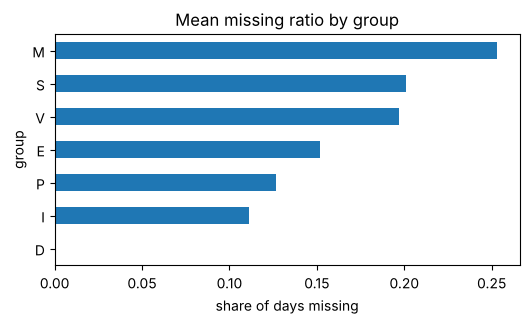

In [9]:
miss.groupby('group')['missing_ratio'].mean().sort_values().plot.barh(figsize=(6, 3), title='Mean missing ratio by group')
plt.xlabel('share of days missing'); plt.show()

**Interpretation:** D features are complete, while M (≈25 % missing), S and V (≈20 %) have the most gaps.
Some features are missing for most of the history – `E7` is 77 % empty and only starts at `date_id` 6969.

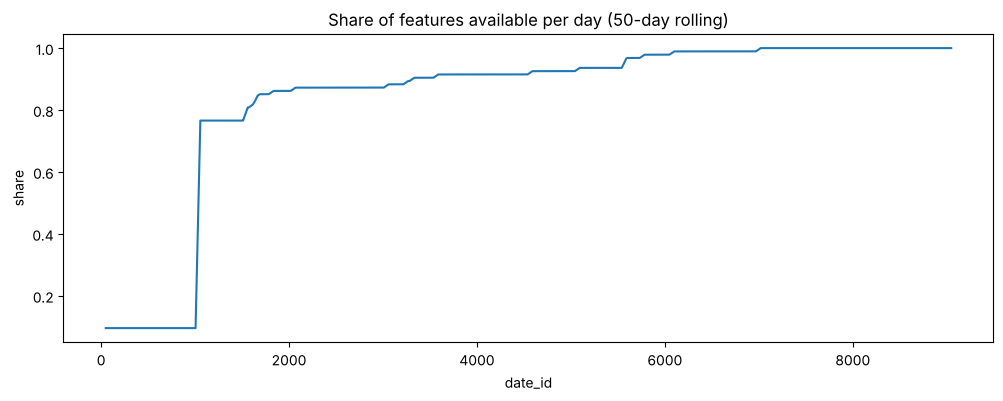

In [10]:
fig, ax = plt.subplots(figsize=(12, 4))
avail = train[feats].notna().mean(axis=1).rolling(50).mean()
ax.plot(train['date_id'], avail)
ax.set(title='Share of features available per day (50-day rolling)', xlabel='date_id', ylabel='share')
plt.show()

**Interpretation:** missing values are not random – they depend on **time**. For the first ≈1,000 days only the
9 D features exist (≈10 % of columns); availability then jumps to ≈77 % and slowly reaches 100 % around
`date_id` 7000. Features were simply not recorded yet, so the right treatment is to drop the earliest days and
carry the last known value forward (section 4), not to fill with values from the future.

### 2.5 Duplicates

In [11]:
print('Duplicated rows             :', train.duplicated().sum())
print('Duplicated date_id          :', train['date_id'].duplicated().sum())
print('Gaps in date_id             :', (train['date_id'].diff().dropna() != 1).sum())
dup_feat = train[feats].duplicated(keep=False)
print('Rows with duplicated features:', dup_feat.sum(), '| last such date_id:', train.loc[dup_feat, 'date_id'].max())

Duplicated rows             : 0
Duplicated date_id          : 0
Gaps in date_id             : 0
Rows with duplicated features: 1003 | last such date_id: 1005


There are no duplicated rows or dates and no gaps in `date_id`. About 1,000 rows share the same feature
values, but all of them are in the first ≈1,000 days, where only the 9 binary D features exist (so few
combinations are possible). They are different days with different returns, not copies, and they disappear
once the early rows are dropped in preprocessing.

## 3. Exploratory data analysis
### 3.1 Target distribution and balance

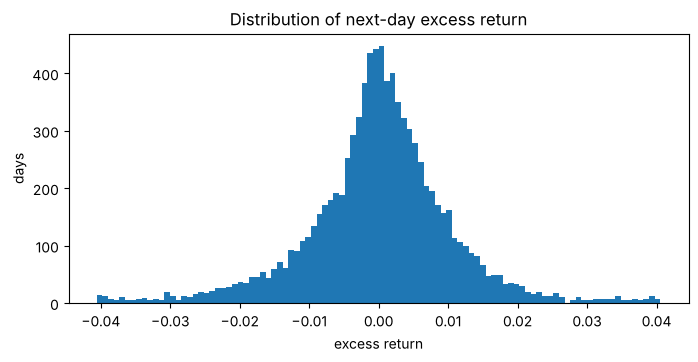

skew: -0.18 | kurtosis: 2.244 | share of positive days: 0.517


In [12]:
y = train[D.TARGET]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(y, bins=100); ax.set(title='Distribution of next-day excess return', xlabel='excess return', ylabel='days')
plt.show()
print('skew:', round(y.skew(), 3), '| kurtosis:', round(y.kurt(), 3), '| share of positive days:', round((y > 0).mean(), 3))

**Interpretation:** the distribution is centred near zero and peaked, with **fat tails** (kurtosis 2.2 vs 0 for a
normal distribution) and a slight left skew (−0.18): large losses are a bit more common than equally large gains.
The target is almost **balanced** – 51.7 % of days are positive – so simply guessing the sign is barely better than
a coin flip.

### 3.2 Outliers

/tmp/ipykernel_153/215334849.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(y, vert=False, flierprops=dict(markersize=2)); axes[0].set(title='Box plot of excess return', xlabel='excess return')


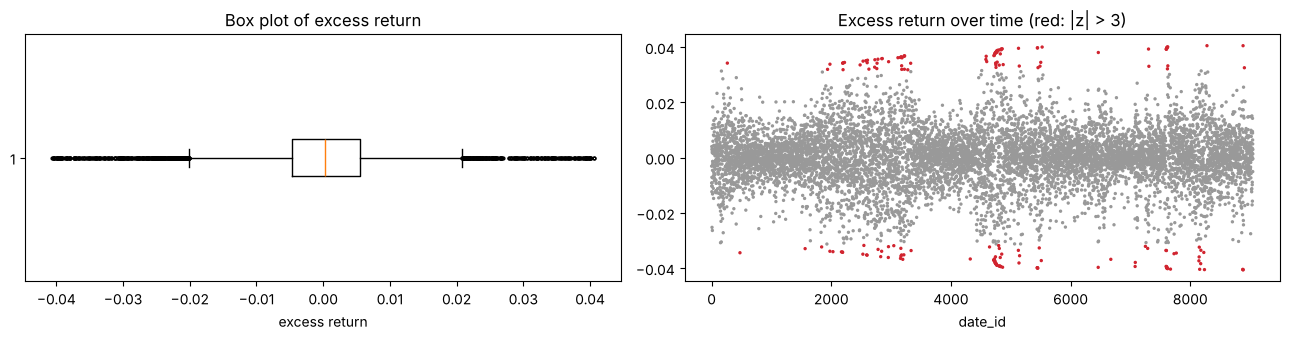

days with |z| > 3: 180 (2.0%; a normal distribution would give 0.3%)
min / max: -0.0406 / 0.0406


In [13]:
z = (y - y.mean()) / y.std()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].boxplot(y, vert=False, flierprops=dict(markersize=2)); axes[0].set(title='Box plot of excess return', xlabel='excess return')
axes[1].scatter(train['date_id'], y, s=2, c=np.where(z.abs() > 3, '#d1242f', '#999999'))
axes[1].set(title='Excess return over time (red: |z| > 3)', xlabel='date_id')
plt.tight_layout(); plt.show()
print('days with |z| > 3:', (z.abs() > 3).sum(), f'({(z.abs() > 3).mean():.1%}; a normal distribution would give 0.3%)')
print('min / max:', round(y.min(), 4), '/', round(y.max(), 4))

**Interpretation:** 180 days (2.0 %) are more than 3 standard deviations from the mean – about 7× more than a
normal distribution would produce. They are **clustered in time** (crisis periods) rather than scattered randomly,
so they are real market events, not data errors. The minimum and maximum are almost exactly ±4.06 %, which suggests
the organisers **clipped** the target. We therefore keep these days: removing them would hide exactly the risky
periods the strategy has to handle.

In [14]:
fz = ((train[feats] - train[feats].mean()) / train[feats].std()).abs()
out = pd.DataFrame({'features_with_|z|>5': (fz > 5).any().groupby(D.group_of).sum(),
                    'max_|z|': fz.max().groupby(D.group_of).max().round(1)})
out

,features_with_|z|>5,max_|z|
D,2,5.5
E,7,23.9
I,1,5.5
M,5,12.0
P,4,13.6
S,2,11.6
V,5,18.1


**Interpretation:** extreme feature values exist in every group, most strongly in E (macro, up to 24 std) and
V (volatility, up to 18 std) – macro and volatility indicators spike in crises. Tree models are insensitive to such
values; for linear models we use standardisation and strong regularisation instead of clipping, so that the
information about crises is not thrown away.

### 3.3 Market growth and volatility over time

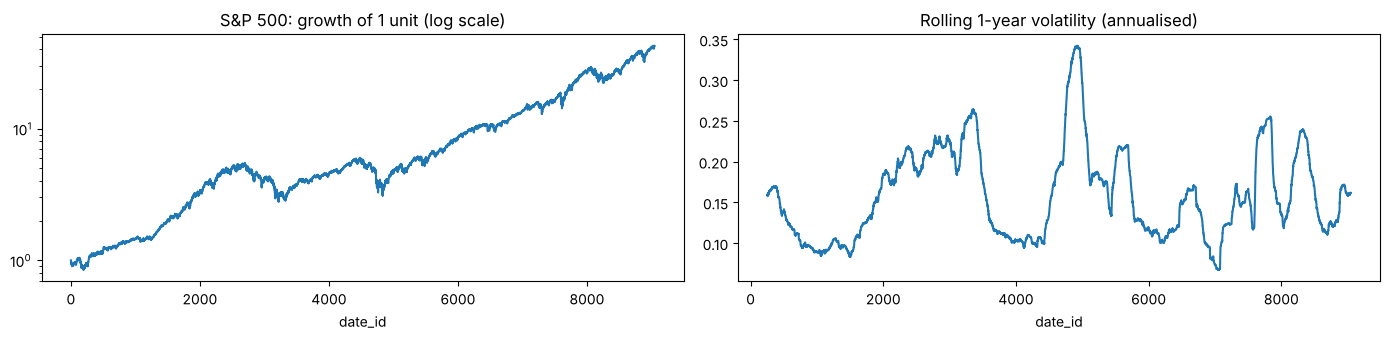

annualised market return: 0.11


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
axes[0].plot(train['date_id'], (1 + train['forward_returns']).cumprod()); axes[0].set_yscale('log')
axes[0].set(title='S&P 500: growth of 1 unit (log scale)', xlabel='date_id')
axes[1].plot(train['date_id'], train['forward_returns'].rolling(252).std() * np.sqrt(252))
axes[1].set(title='Rolling 1-year volatility (annualised)', xlabel='date_id')
plt.tight_layout(); plt.show()
print('annualised market return:', round((1 + train['forward_returns']).prod() ** (252 / len(train)) - 1, 3))

**Interpretation:** the market grows about 11 % per year, but not smoothly. There are two clear drawdowns
(around `date_id` 2200–3300 and 4700–5000; the dates are anonymised, the second one probably corresponds to the
2008 crisis). Volatility moves in **regimes**: calm periods around 10 % per year and stress periods of 25–34 %.
The sharpest drawdown coincides with the volatility peak (≈34 %), so **big losses come together with high
volatility**.

### 3.4 Can returns or volatility be predicted from the past?

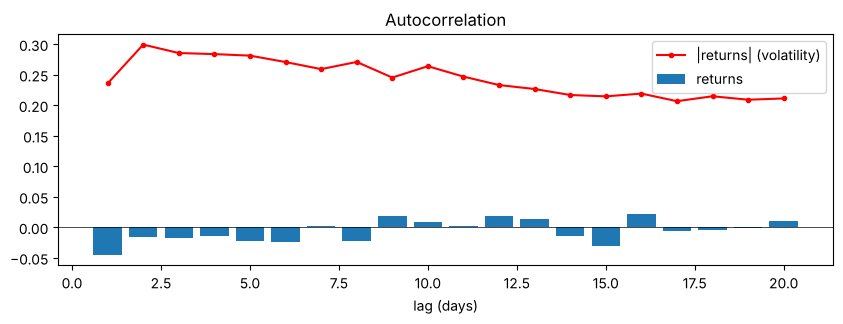

In [16]:
lags = range(1, 21)
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(lags, [y.autocorr(l) for l in lags], label='returns')
ax.plot(lags, [y.abs().autocorr(l) for l in lags], 'r.-', label='|returns| (volatility)')
ax.axhline(0, color='k', lw=.5); ax.legend(); ax.set(title='Autocorrelation', xlabel='lag (days)')
plt.show()

**Interpretation:** returns themselves are almost uncorrelated with their past (lag-1 autocorrelation −0.045, a hint
of short-term mean reversion), so yesterday says little about the direction of tomorrow. **Absolute** returns are
strongly autocorrelated (≈0.24–0.30) and decay very slowly up to lag 20: calm days follow calm days and volatile
days follow volatile days (*volatility clustering*). This is the most useful finding of the EDA: **the size of the
risk is predictable even though the direction is not**.

### 3.5 Feature distributions

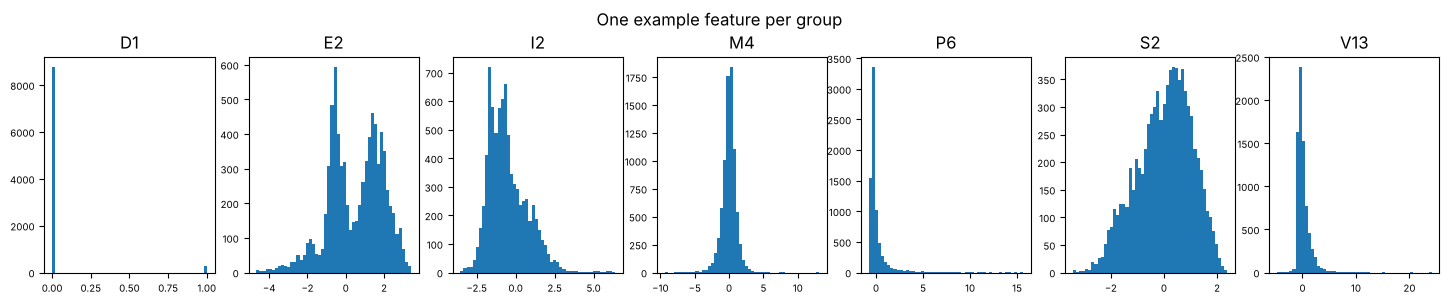

,min,median,max
D,-1.23,2.04,5.36
E,-4.91,0.49,6.16
I,-0.86,-0.08,1.00
M,-0.75,0.40,3.63
P,-1.61,0.01,5.32
S,-0.75,0.04,1.14
V,-0.05,0.74,4.01


In [17]:
examples = ['D1', 'E2', 'I2', 'M4', 'P6', 'S2', 'V13']
fig, axes = plt.subplots(1, len(examples), figsize=(18, 2.8))
for ax, c in zip(axes, examples):
    ax.hist(train[c].dropna(), bins=50); ax.set_title(c); ax.tick_params(labelsize=7)
plt.suptitle('One example feature per group', y=1.05); plt.show()
train[feats].skew().groupby(D.group_of).agg(['min', 'median', 'max']).round(2)

**Interpretation:** the groups look very different. `D1` is binary and rare (equal to 1 on only 3 % of days);
`E2` is **bimodal**, which suggests two macro regimes; `M4` is symmetric but very peaked with long tails; `P6` and
`V13` are strongly **right-skewed** (rare large spikes); `S2` and `I2` are roughly symmetric. Across all features
skewness ranges from −4.9 to 6.2. Different scales and shapes confirm that features must be standardised before a
linear model, while tree models can use them as they are.

### 3.6 Relationship between features and the target

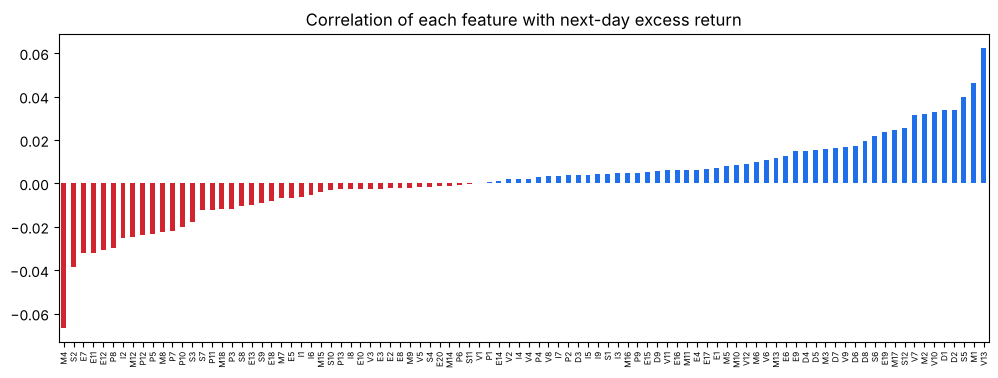

,corr
M4,-0.067
S2,-0.038
E7,-0.032
E11,-0.032
E12,-0.031
D1,0.034
D2,0.034
S5,0.040
M1,0.046
V13,0.062


In [18]:
tr0 = D.drop_early_rows(train)
corr = tr0[feats].corrwith(tr0[D.TARGET]).dropna().sort_values()
fig, ax = plt.subplots(figsize=(12, 4))
corr.plot.bar(ax=ax, color=['#d1242f' if v < 0 else '#1f6feb' for v in corr])
ax.set_title('Correlation of each feature with next-day excess return'); ax.tick_params(axis='x', labelsize=6)
plt.show()
pd.concat([corr.head(5), corr.tail(5)]).to_frame('corr').round(3)

**Interpretation:** every feature is only weakly related to the target – the strongest correlations are about
±0.06 (`M4` −0.067, `V13` +0.062, `M1` +0.046). With ≈8,000 days a correlation of 0.06 is statistically
detectable, but it explains less than 0.5 % of the variance. Any model will therefore make many wrong calls,
and the strategy must not bet too aggressively on its predictions.

/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


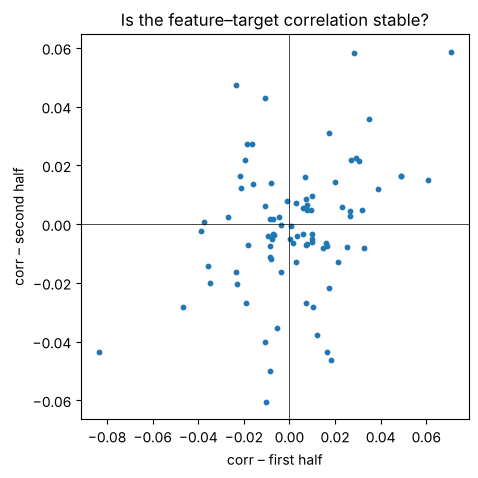

rank correlation between halves: 0.241


In [19]:
half = len(tr0) // 2
c1 = tr0.iloc[:half][feats].corrwith(tr0.iloc[:half][D.TARGET])
c2 = tr0.iloc[half:][feats].corrwith(tr0.iloc[half:][D.TARGET])
plt.figure(figsize=(5, 5)); plt.scatter(c1, c2, s=10)
plt.axhline(0, c='k', lw=.5); plt.axvline(0, c='k', lw=.5)
plt.xlabel('corr – first half'); plt.ylabel('corr – second half'); plt.title('Is the feature–target correlation stable?')
plt.show()
print('rank correlation between halves:', round(c1.corr(c2, method='spearman'), 3))

**Interpretation:** if the relationships were stable, the points would lie on the diagonal. Instead the rank
correlation between the two halves is only 0.24, and several features even change sign. A model fitted on the
past may not hold in the future, so validation must be **time-based** (train on the past, test on the future) and
models must be strongly regularised.

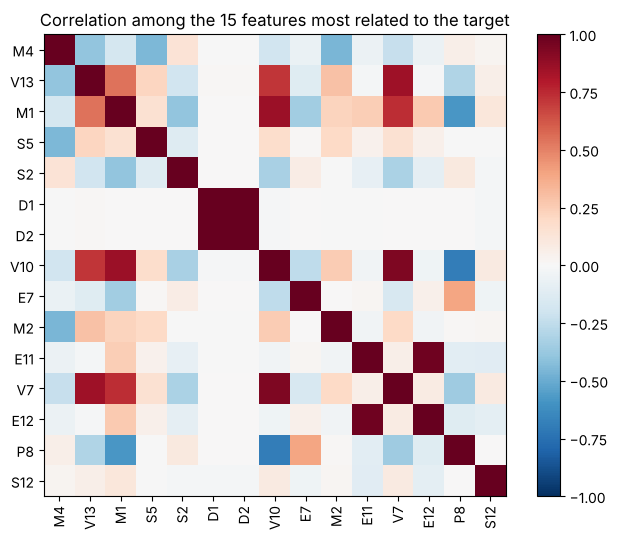

In [20]:
top = corr.abs().sort_values(ascending=False).index[:15]
plt.figure(figsize=(8, 6))
plt.imshow(tr0[top].corr(), cmap='RdBu_r', vmin=-1, vmax=1)
plt.xticks(range(len(top)), top, rotation=90); plt.yticks(range(len(top)), top)
plt.colorbar(); plt.title('Correlation among the 15 features most related to the target'); plt.show()

**Interpretation:** several of the most target-related features carry overlapping information (dark red blocks):
`D1` and `D2` are identical on every day, `E11` and `E12` correlate at 0.97, and the volatility/market block
`V7`, `V10`, `V13`, `M1` correlates at 0.55–0.93. This **multicollinearity** makes plain linear regression
coefficients unstable, which is another reason to use Ridge/ElasticNet regularisation.

## 4. Preprocessing

| Step | What we do | Why |
|------|------------|-----|
| 1. Drop early rows | Remove the first days where more than 50 % of features are missing (`D.drop_early_rows`) | Before ≈`date_id` 1006 only the D dummies exist; imputing 90 % of a row would invent data (section 2.4). |
| 2. Lagged returns | Add yesterday's returns as `lagged_*` columns (`D.add_lagged_returns`) | The test set provides these columns; volatility-targeting and momentum rules need recent returns. Shifting by one day guarantees no future information. |
| 3. Imputation | Forward-fill, then fill what is left with **training** medians (`D.fill_missing`) | Indicators are published over time, so the last known value is the most realistic estimate; medians are robust to the outliers in section 3.2 and come only from the training period. Tree models skip this step because LightGBM handles missing values itself. |
| 4. Scaling | `StandardScaler` inside the Ridge/ElasticNet pipeline | Feature scales differ by orders of magnitude (section 2.3) and regularisation penalises all coefficients equally, so features must be on the same scale. The scaler is fitted on training data only. |
| 5. Encoding | None | All columns are numeric and the D features are already 0/1 indicators (section 2.2). |
| 6. Outliers | Kept | Extreme days are real crisis events and the target is already clipped (section 3.2); regularisation and trees limit their influence. |
| 7. Duplicates | Nothing to remove | No duplicated rows or dates; repeated feature rows disappear with step 1 (section 2.5). |
| 8. Split | Chronological (walk-forward and last-20 % hold-out) | Random splits would train on the future (section 3.6). |

In [21]:
df = D.add_lagged_returns(D.drop_early_rows(train))
print('rows before:', len(train), '→ after dropping early rows:', len(df), '| first date_id kept:', df['date_id'].iloc[0])
print('missing values before imputation:', int(df[feats].isna().sum().sum()))
X_filled, medians = D.fill_missing(df[feats])
print('missing values after imputation :', int(X_filled.isna().sum().sum()))
df[['date_id', 'forward_returns', 'lagged_forward_returns']].head(3)

rows before: 9048 → after dropping early rows: 8042 | first date_id kept: 1006
missing values before imputation: 52165


missing values after imputation : 0


,date_id,forward_returns,lagged_forward_returns
0,1006,-0.000669,NaN
1,1007,0.005348,-0.000669
2,1008,0.001996,0.005348


After preprocessing, 8,042 days remain (from `date_id` 1006). The table shows that `lagged_forward_returns` on each
day equals the previous day's `forward_returns`, so the models only use information that is known at decision
time.

## 5. Baseline models

Every baseline outputs a **daily position in [0, 2]** and is scored with the competition metric. Models live in
`src/models.py`:

| Baseline | Idea |
|----------|------|
| `constant_1` | Buy & hold: position = 1 every day. **The benchmark to beat.** |
| `best_constant` | The constant position that scored best on the training period. |
| `vol_target_21d`, `vol_target_63d` | Volatility targeting: position = long-run vol / recent vol (1 or 3 months), capped at 1.5. Motivated by volatility clustering (section 3.4). |
| `momentum_252d` | Trend rule: position 1.2 if the past year was positive, else 0.6. |
| `ridge`, `elasticnet` | Regularised linear regression on all 94 features predicting the next-day excess return; the standardised prediction is mapped to `1 + 0.5 × signal`. |
| `lightgbm` | Gradient-boosted trees (small, regularised) on all features – a non-linear version of the same idea. |

**Validation – walk-forward (expanding window).** We train on everything up to a date and score the next block of
≈1,340 days, five times. This mimics real use: the model always predicts days it has not seen.

```
fold 0: [train..........][valid]
fold 1: [train..................][valid]
...
fold 4: [train..........................................][valid]
```

In [22]:
folds = list(D.walk_forward_folds(len(df), n_folds=5))
pd.DataFrame([{'fold': k, 'train_days': len(t), 'valid_days': len(v),
               'valid_from': df.date_id.iloc[v[0]], 'valid_to': df.date_id.iloc[v[-1]]}
              for k, (t, v) in enumerate(folds)]).set_index('fold')

,train_days,valid_days,valid_from,valid_to
fold,,,,
0,1342,1340,2348,3687
1,2682,1340,3688,5027
2,4022,1340,5028,6367
3,5362,1340,6368,7707
4,6702,1340,7708,9047


In [23]:
models = M.baseline_zoo()
table, per_fold = U.compare_models(models, df, folds)
table.round(3)

,mean_score,std_score,folds_beating_market,mean_position,ann_vol
model,,,,,
vol_target_21d,0.452,0.568,4,1.156,0.166
momentum_252d,0.436,0.449,3,1.056,0.171
vol_target_63d,0.420,0.490,2,1.147,0.170
constant_1,0.418,0.514,0,1.000,0.175
elasticnet,0.390,0.499,2,1.258,0.285
lightgbm,0.385,0.411,1,1.047,0.244
ridge,0.327,0.425,1,1.312,0.292
best_constant,0.315,0.407,1,0.640,0.114


**Interpretation:** only the rule-based strategies beat buy & hold (0.418). Volatility targeting over 21 days is the
best baseline (0.452) and beats the market in 4 of 5 folds, with slightly *lower* volatility than the market
(16.6 % vs 17.5 %). The models that predict the return from the 94 features – ElasticNet, LightGBM and Ridge –
score below buy & hold: their positions swing so much that the strategy becomes far more volatile (24–29 %) and
is penalised by the metric. The best constant from the past does not carry over to the future.

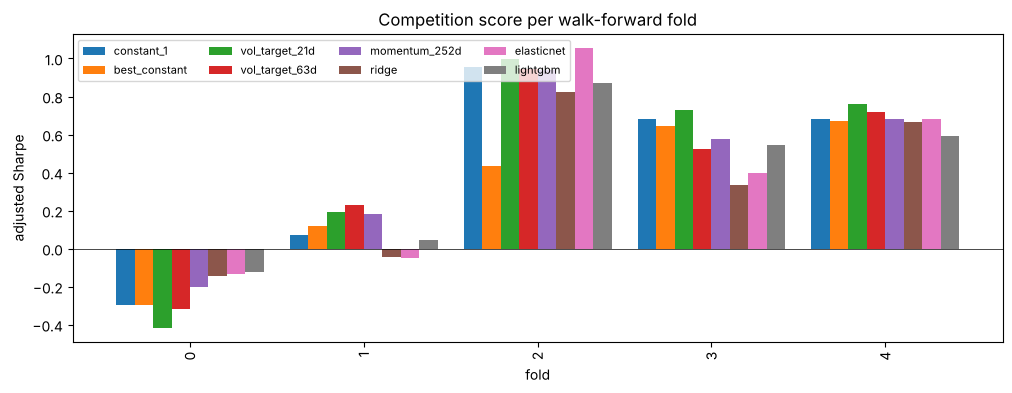

In [24]:
scores = pd.DataFrame({name: res['score'] for name, res in per_fold.items()})
ax = scores.plot.bar(figsize=(12, 4), width=0.85)
ax.axhline(0, color='k', lw=.5)
ax.set(title='Competition score per walk-forward fold', xlabel='fold', ylabel='adjusted Sharpe')
ax.legend(ncol=4, fontsize=8, loc='upper left')
plt.show()

**Interpretation:** scores change a lot between periods – every model is negative in fold 0 (a market drawdown)
and close to 1 in fold 2. The period matters more than the model, so a single train/test split could easily be
misleading; averaging over five folds gives a fairer comparison.

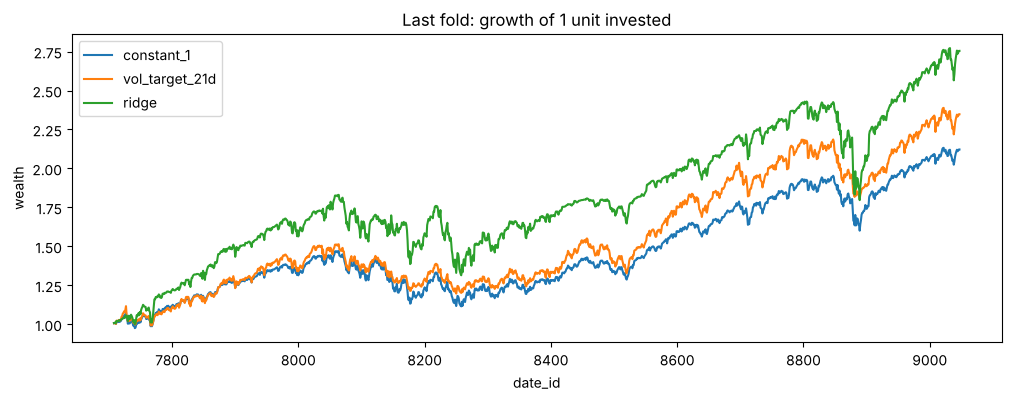

In [25]:
tr_idx, va_idx = folds[-1]
valid = df.iloc[va_idx]
fig, ax = plt.subplots(figsize=(12, 4))
for name in ['constant_1', 'vol_target_21d', 'ridge']:
    m = models[name].fit(df.iloc[tr_idx])
    bt = U.backtest(valid, m.predict_position(valid))
    ax.plot(bt['date_id'], bt['strategy_wealth'], label=name)
ax.set(title='Last fold: growth of 1 unit invested', xlabel='date_id', ylabel='wealth'); ax.legend()
plt.show()

**Interpretation:** in the last fold Ridge ends with the most money (≈2.75× vs ≈2.1× for buy & hold), yet its
score is *lower* than buy & hold because of its large swings. **Making more money is not the same as scoring
higher** – the metric rewards return per unit of risk.

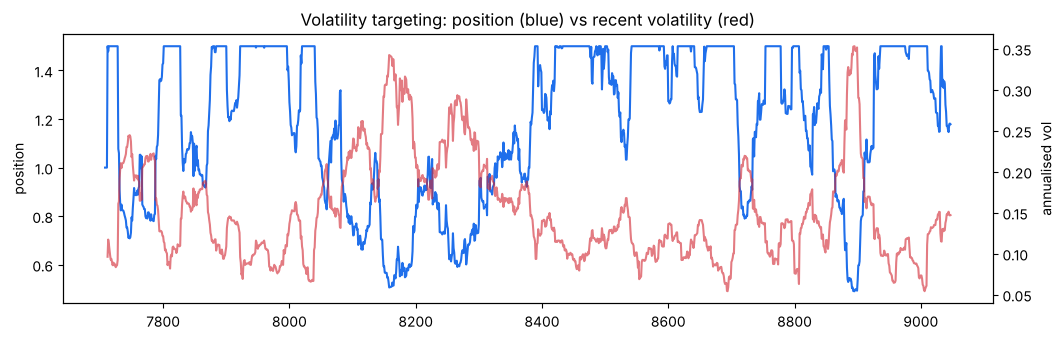

In [26]:
vt = models['vol_target_21d'].fit(df.iloc[tr_idx])
fig, ax1 = plt.subplots(figsize=(12, 3.5))
ax1.plot(valid['date_id'], vt.predict_position(valid), color='#1f6feb', label='position'); ax1.set_ylabel('position')
ax2 = ax1.twinx()
ax2.plot(valid['date_id'], M.realised_vol(valid['lagged_forward_returns'], 21) * np.sqrt(252),
         color='#d1242f', alpha=.6, label='21-day vol')
ax2.set_ylabel('annualised vol')
ax1.set_title('Volatility targeting: position (blue) vs recent volatility (red)')
plt.show()

**Interpretation:** the position is the mirror image of volatility – it stays at the 1.5 cap in calm periods and
drops sharply (to ≈0.5) when volatility spikes. The strategy is therefore more invested when risk is low and steps
aside during turbulent periods, which is exactly what the EDA suggested.

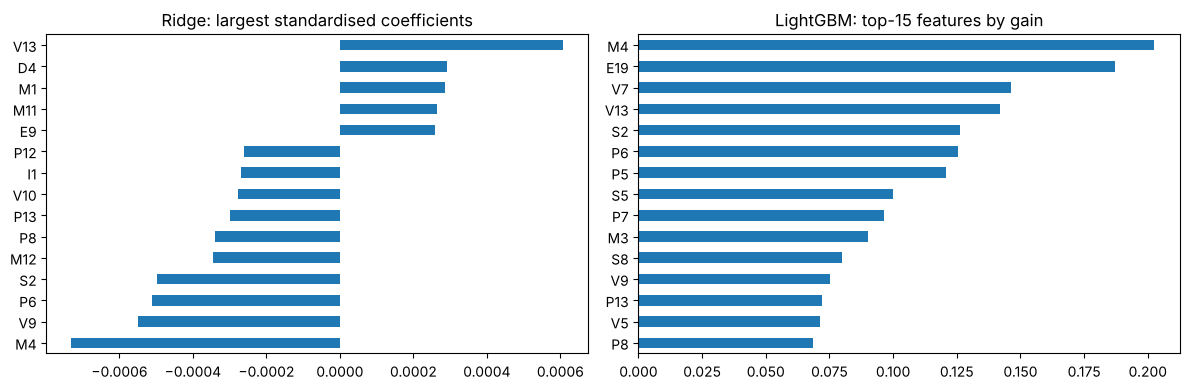

Features in both top-15 lists: ['M4', 'P13', 'P6', 'P8', 'S2', 'V13', 'V9']


In [27]:
ridge = models['ridge'].fit(df.iloc[tr_idx])
coef = ridge.coefficients().head(15)
lgbm = models['lightgbm'].fit(df.iloc[tr_idx])
imp = lgbm.feature_importance().head(15)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
coef.sort_values().plot.barh(ax=axes[0], title='Ridge: largest standardised coefficients')
imp.sort_values().plot.barh(ax=axes[1], title='LightGBM: top-15 features by gain')
plt.tight_layout(); plt.show()
print('Features in both top-15 lists:', sorted(set(imp.index) & set(coef.index)))

**Interpretation:** the two very different models agree on 7 of their 15 most important features
(`M4`, `P13`, `P6`, `P8`, `S2`, `V13`, `V9`), and `M4` / `V13` were also the strongest correlations in
section 3.6. So there is some consistent information in market-dynamics, price, sentiment and volatility
features – it is just too weak to be used naively.

## 6. Kaggle submission / held-out evaluation

**Kaggle submission.** The competition closed on 2026-06-26 and Kaggle has disabled late submissions
("Submissions have been disabled for this competition", screenshot in `submissions/`). A submission notebook
(`kaggle_submission.ipynb`) for the best baseline was still prepared and checked with the official
`kaggle_evaluation` gateway in a local dry run.

**Held-out evaluation.** As required for competitions without late submissions, we hold out **20 % of `train.csv`**
as a test set and report the competition metric on it. We use `train_test_split(..., test_size=0.2, shuffle=False)`
(`D.holdout_split`) – i.e. the **last** 20 % of days – instead of a random split: the rows are consecutive days,
and a random split would let the models learn from days that come after the test days. (`random_state` has no
effect without shuffling.) Models are trained on the first 80 % only.

In [28]:
full = D.add_lagged_returns(train)
hold_train, hold_test = D.holdout_split(full, test_size=0.2)
hold_train = D.drop_early_rows(hold_train)
print('train:', len(hold_train), 'days | test:', len(hold_test), 'days (date_id',
      hold_test.date_id.iloc[0], '–', hold_test.date_id.iloc[-1], ')')
holdout = U.holdout_evaluate(M.baseline_zoo(), hold_train, hold_test)
holdout[['score', 'ann_return', 'ann_vol', 'mean_position']].round(3)

train: 6232 days | test: 1810 days (date_id 7238 – 9047 )


,score,ann_return,ann_vol,mean_position
model,,,,
vol_target_21d,0.691,0.155,0.171,1.156
constant_1,0.624,0.146,0.177,1.000
best_constant,0.618,0.124,0.141,0.800
momentum_252d,0.575,0.146,0.192,1.110
vol_target_63d,0.547,0.133,0.178,1.140
elasticnet,0.524,0.192,0.243,1.054
lightgbm,0.521,0.203,0.250,1.083
ridge,0.398,0.208,0.287,1.330


**Interpretation:** the hold-out confirms the walk-forward ranking at the top: **volatility targeting (21 days)
scores 0.691**, ahead of buy & hold (0.624), with a slightly higher return at about the same volatility. All
feature-based models (ElasticNet, LightGBM, Ridge) again lose to buy & hold even though they earn the highest raw
returns (19–21 % per year), because their volatility is much higher.

**Comparison with the leaderboard.** The final leaderboard (screenshot `submissions/leaderboard_top.png`) is led by
scores of **3.85** (1st place) and **3.84** (2nd); the top 8 teams score between 3.23 and 3.85. Our held-out score of
**0.691** is far lower, but the two numbers are **not directly comparable**: the leaderboard was scored on a short
live period after the competition ended (a few months), while our hold-out covers ≈7 years (1,810 days) of training
data. Scores over short periods swing strongly – our own walk-forward folds range from below 0 to ≈1 (section 5) –
and a period in which the market rose steadily with low volatility produces very high Sharpe ratios. A fair
comparison would need the same test period, which is no longer possible because submissions are disabled.

## 7. Conclusion

**Key findings**
- **The direction of returns is almost unpredictable:** the target is nearly balanced (51.7 % positive days), has
  almost no autocorrelation, and every feature correlates with it by at most ≈0.06 – and these correlations are
  unstable over time.
- **Risk is predictable:** volatility clusters strongly, and large losses happen in high-volatility periods.
- **The best baseline uses this:** volatility targeting (21 days) beats buy & hold both in walk-forward validation
  (0.452 vs 0.418, 4 of 5 folds) and on the 20 % hold-out (0.691 vs 0.624).
- **Feature-based return prediction does not beat buy & hold yet:** Ridge, ElasticNet and LightGBM earn more but
  take far more risk, which the metric penalises.

**Next steps (Assignment 2)**
- Combine a weak but regularised return signal with volatility-based position sizing instead of using either alone.
- Build features from lagged returns (realised volatility over several windows, momentum, drawdown).
- Tune how strongly predictions move the position (the `scale` of the signal → position mapping) with walk-forward
  validation, and keep the strategy's volatility below 1.2× the market.